# You Can't Raise DAU by Staring at the DAU Chart — User Segment Analysis Practice

A single-line DAU graph squashes everything into one point: whether new users are settling in, whether heavy
users are showing signs of churn, whether dormant users are coming back to life. This notebook splits the users of a fictional habit-tracker app, "RoutineLog," into **5 segments**
and looks at the health of the service from several angles using the **movement (Flow)** between segments and ratio metrics.
The figures and tables may look fairly complex, but once you move them into SQL, you will find they
run on a surprisingly simple data structure.

The analysis starts from two source tables.

| Table | Grain | Role |
| :-- | :-- | :-- |
| `user_master` | user_id (one row per user) | Per-user signup (first record) info — when did they first meet our service? |
| `user_activity` | user_id × event_date | Records of the days a user logged a habit check-in — when did they actually use the service? |

- **1.3.2.** Build 3 derived metrics (`days_since_signup`, `active_day_count`, `last_active_date`) from the two tables and classify users by fixed rules into 5 segments (new / heavy / light / risk / dormant). Cross segments with "logged today?" to see the composition of DAU as well.
- **1.3.3.** Stack a month of date × user segment snapshots and attach yesterday's segment with `lag` to build a data mart that can track segment changes.
- **1.3.4.** Analyze that data mart from three angles: distribution (Stock) · transition matrix (Flow) · ratio metrics (HURR/CURR/Heavy Loss/Light Loss/Reactivation).
- **1.3.5.** Self-join the month of data mart rows to track where users who were heavy or new 30 days ago ended up today (N-day change).

All queries run directly on the example CSVs with **DuckDB**.


## 1.3.1. Preparing the practice data

The first cell below installs the dependencies, and the next one sets up the practice environment (connection, target-date constant, table registration).
If you don't have the data yet, run `python generate_data.py` in a terminal first to create the example
data (`data/user_master.csv`, `data/user_activity.csv`).

> **[Apply to your data]** Change the analysis target date in one place only: the `TARGET` constant. Each query
> inserts this value via f-string, and the loading date range in 1.3.3 is derived from it as well.


### Two tables: user_master and user_activity

The practice needs 2 tables: `user_master`, which records each user's signup info, and
`user_activity`, which records the users' behavior log. The reason for keeping them as two separate tables is that the
data they hold is different in nature. The first-record date goes into a static master table that is written once per user,
while the daily records go into a log table that grows every day. In RoutineLog, "activity" means logging a habit
check-in that day rather than merely opening the app, so one row in `user_activity` means "this user logged something on this day."
Because the two datasets differ in refresh cadence and in the context they are used in, keeping them as separate tables
is better both for operating the mart and for analysis.

The cell below registers the two CSVs as DuckDB tables, and every query after that refers to them by
table name. The analysis target date lives in a single `TARGET` constant, inserted into each SQL via a Python f-string (`DATE '{TARGET}'`). To change the target date, you only edit this constant, and the loading date range in 1.3.3 is derived from it too. DuckDB is a lightweight analytical DB that runs SQL directly inside Python with no separate server
to install. The SQL used here is almost entirely standard syntax, so porting it to your company's warehouse (BigQuery,
Redshift, etc.) only takes tweaking a few functions.

> **[Apply to your data]** Swap in the two tables from your own service —
> `user_master(user_id, first_active_date)`, `user_activity(user_id, event_date)`.


In [1]:
# Install dependencies
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()   # one in-memory connection reused throughout the notebook
SEG_ORDER = ["new", "heavy", "light", "risk", "dormant"]
TARGET = "2026-05-20"    # analysis target date

# Register the two CSVs as tables once - later queries refer to them by table name
for t in ["user_master", "user_activity"]:
    q = f"CREATE TABLE {t} AS SELECT * FROM read_csv_auto('data/{t}.csv')"
    con.execute(q)
con.execute("SELECT * FROM user_activity").df().head()

,user_id,event_date
0,user_032,2026-01-27
1,user_144,2026-01-27
2,user_144,2026-01-28
3,user_123,2026-01-29
4,user_144,2026-01-29


## 1.3.2. Classifying 5 segments from 3 derived metrics

Looking at the `user_master` or `user_activity` table alone makes it hard to tell which segment an
individual user belongs to. These two tables are only the raw material for the analysis;
to tell segments apart we need one more processing step.

The 5 segments (new, heavy, light, risk, dormant) are determined by the following 3 axes.

| Axis | Meaning |
| :-- | :-- |
| `days_since_signup` | How many days since signup (first record)? |
| `active_day_count` | On how many of the last 7 days did the user log something? |
| `last_active_date` | When was the most recent record? |

It is not part of the segment definition, but we also build "logged today?" (`d0_active`) at the same time.
This column is used later to look at the DAU composition by segment.


### 1.3.2.1. Computing the derived metrics


`LEFT JOIN` `user_master` with `user_activity` and aggregate per user, and you get all the derived metrics
in one pass. The result is stored in the `user_metrics` table, and the classification query in the next step
uses this table as its input.

The `count_if` in the query is a DuckDB aggregate function that counts "how many rows satisfy the condition"
(the same role as BigQuery's `COUNTIF` or Snowflake's `COUNT_IF`). If your company's data warehouse lacks such a
function, rewrite it as `SUM(CASE WHEN … THEN 1 ELSE 0 END)`. The "logged today?" flag (`d0_active`) is built
in a similar way, using `MAX(CASE WHEN …)` to produce a 0/1 flag.


In [3]:
# Derived metrics — LEFT JOIN user_master with user_activity and aggregate per user
con.execute(f"""
CREATE OR REPLACE TABLE user_metrics AS
SELECT
  m.user_id,
  -- 1. Days since signup (first record) (signup day = 0)
  datediff('day', m.first_active_date, DATE '{TARGET}') AS days_since_signup,
  -- 2. Number of days with a record in the last 7 days (including the target date)
  count_if(a.event_date BETWEEN DATE '{TARGET}' - INTERVAL 6 DAY
                            AND DATE '{TARGET}') AS active_day_count,
  -- 3. Last record date (always present, since the signup day is guaranteed to have a record)
  max(CASE WHEN a.event_date <= DATE '{TARGET}'
      THEN a.event_date END) AS last_active_date,
  -- (+) Logged something today?
  max(CASE WHEN a.event_date = DATE '{TARGET}'
      THEN 1 ELSE 0 END) AS d0_active
FROM user_master m LEFT JOIN user_activity a USING (user_id)
GROUP BY m.user_id, m.first_active_date
""")
con.execute("SELECT * FROM user_metrics ORDER BY user_id").df().head()

,user_id,days_since_signup,active_day_count,last_active_date,d0_active
0,user_001,0,1.0,2026-05-20,1
1,user_002,0,1.0,2026-05-20,1
2,user_003,0,1.0,2026-05-20,1
3,user_004,0,1.0,2026-05-20,1
4,user_005,0,1.0,2026-05-20,1


### 1.3.2.2. Segment mapping


Next, it's time to define the segment mapping on top of these derived metrics. The 3 metrics in `user_metrics` are
classified into 5 segments by **fixed rules** in a single `CASE WHEN` step. The classification rules are as follows.

| Segment | Rule |
| :-- | :-- |
| `new` | Within 7 days of signup (`days_since_signup < 7`) |
| `heavy` | Day 8+ since signup & logged on 5 or more of the last 7 days |
| `light` | Day 8+ since signup & logged on 1-4 of the last 7 days |
| `risk` | 0 records in the last 7 days & last record 7-30 days ago |
| `dormant` | 0 records in the last 7 days & last record more than 30 days ago |

> Why new is 7 days rather than one day — the first week after signup is when users learn the service, so
> "are they still here after the first week?" matters more than whether they logged on any given day. Once 7 days have passed,
> users move naturally into heavy/light depending on how many days they logged in the past week, or into risk if they logged nothing.
>
> The risk/dormant split is decided by the last record date alone — `active_day_count = 0` already
> means there were no records in the last 7 days, so there is no need to separately check
> "was the last record before 7 days ago?"

Let's classify each user into the 5 segments by these rules.


In [4]:
# Classify into 5 segments by fixed rules - the input is user_metrics
seg = con.execute(f"""
SELECT
  *,
  CASE
    WHEN days_since_signup < 7           THEN 'new'
    WHEN active_day_count >= 5           THEN 'heavy'
    WHEN active_day_count BETWEEN 1 AND 4 THEN 'light'
    -- active_day_count = 0 means no record in the last 7 days, so
    -- risk vs. dormant only needs to check whether the last record is within 30 days.
    WHEN last_active_date >= DATE '{TARGET}' - INTERVAL 30 DAY THEN 'risk'
    ELSE 'dormant'
  END AS user_seg
FROM user_metrics
ORDER BY user_id;
""").df()
print(seg["user_seg"].value_counts().reindex(SEG_ORDER))

user_seg
new        16
heavy      39
light      72
risk       53
dormant    20
Name: count, dtype: int64


Pulling one user from each segment so that all 5 segments appear shows at a glance
how the 3 metrics collapse into a single segment.

In [5]:
# Pick one representative user from each segment
sample = seg.groupby("user_seg").first().reindex(SEG_ORDER).reset_index()
sample[["user_seg", "user_id", "days_since_signup",
        "active_day_count", "last_active_date"]]

,user_seg,user_id,days_since_signup,active_day_count,last_active_date
0,new,user_001,0,1.0,2026-05-20
1,heavy,user_017,44,6.0,2026-05-20
2,light,user_018,54,1.0,2026-05-19
3,risk,user_021,87,0.0,2026-04-22
4,dormant,user_026,65,0.0,2026-04-16


"Logged today?" is not considered when defining the segments, but because we built the today flag (`d0_active`)
as a separate column, we can also aggregate DAU by segment. The sum of the right-hand column is today's
DAU. The same DAU means something different on a day with many heavy users than on a day with many new users.


In [6]:
# Users who logged today, by segment — DAU layered on top of the Stock
dau_by_seg = (seg.groupby("user_seg")
              .agg(users=("user_id", "count"),
                   active_today=("d0_active", "sum"))
              .reindex(SEG_ORDER))
dau_by_seg.loc["total"] = dau_by_seg.sum()
dau_by_seg.astype(int)

,users,active_today
user_seg,,
new,16,11
heavy,39,30
light,72,29
risk,53,0
dormant,20,0
total,200,70


## 1.3.3. Building a data mart that can track segment changes

The results shown in 1.3.2 are a snapshot at a single point in time — the **Stock** described in the book. With this table
you can see how users are distributed across the segments as of the target date. But
to see how segments change over time, you need a **data mart that holds yesterday's and today's segments
side by side in one row**.

1. Of the users who were heavy yesterday, how many dropped to light today? (Heavy Loss)
2. Of the users who were risk yesterday, who came back to activity today? (Reactivation)
3. Are the users who were heavy yesterday still heavy today? (HURR)
4. Did new users reaching day 8 since signup settle into heavy/light, or fall into risk? (New Activation/New Loss)

Instead of computing yesterday and today separately in one query, we'll build the data mart as date × user snapshots. For each date, we treat that day as the target date, repeat the metric computation and segment classification from 1.3.2, and stack the results; "yesterday's segment" is then taken from the same user's row for the previous date.

First, add a date axis to the metric query from 1.3.2.1. Build the list of dates to load (31 days up to the target date TARGET, 2026-04-20 ~ 2026-05-20) with generate_series (GENERATE_DATE_ARRAY in BigQuery) and join it with the user master; each user then gets one row per date, and each row's target_date plays the role of the target date. Users who had not signed up yet on a given date are filtered out by the join condition (first_active_date <= target_date). The metric definitions are the same as in 1.3.2.1, so when adapting to your data — say, extending the "last 7 days" activity window to 14 days — change INTERVAL 6 DAY in both the 1.3.2.1 query and the user_metrics_daily query below.

> **[Apply to your data]** The loading range is derived as `TARGET - INTERVAL 30 DAY ~ TARGET`. To stack a longer
> span, increase this `30 DAY`, but you also need another 30 days of logs before the start date
> to be able to classify the segment as of 30 days earlier.


In [7]:
# Add a date axis to the metric query from 1.3.2.1 - compute the metrics per date × user
con.execute(f"""
CREATE OR REPLACE TABLE user_metrics_daily AS
SELECT
  d.target_date::DATE AS target_date, m.user_id,
  datediff('day', m.first_active_date, d.target_date) AS days_since_signup,
  count_if(a.event_date BETWEEN d.target_date - INTERVAL 6 DAY
                            AND d.target_date) AS active_day_count,
  max(CASE WHEN a.event_date <= d.target_date
      THEN a.event_date END) AS last_active_date
FROM generate_series(DATE '{TARGET}' - INTERVAL 30 DAY, DATE '{TARGET}',
                     INTERVAL 1 DAY) AS d(target_date)
JOIN user_master m ON m.first_active_date <= d.target_date
LEFT JOIN user_activity a USING (user_id)
GROUP BY d.target_date, m.user_id, m.first_active_date
""")

Next, apply the CASE from 1.3.2.2 as-is to these daily metrics to get each day's segment, and fill in yesterday's segment (user_seg_from) with the window function lag. lag(user_seg) OVER (PARTITION BY user_id ORDER BY target_date) is a standard SQL function that, when the same user's rows are lined up in date order, returns the user_seg of the immediately preceding row. When there is no preceding row — for example, a user who signed up today — it returns NULL. The result, holding today's and yesterday's segments in one row, is loaded into the mart_user_segment table.


In [8]:
# Apply the CASE from 1.3.2.2 per date, fill yesterday's segment with lag, and load into the mart
con.execute("""
CREATE OR REPLACE TABLE mart_user_segment AS
WITH seg AS (
  SELECT target_date, user_id,
    CASE
      WHEN days_since_signup < 7           THEN 'new'
      WHEN active_day_count >= 5           THEN 'heavy'
      WHEN active_day_count BETWEEN 1 AND 4 THEN 'light'
      WHEN last_active_date >= target_date - INTERVAL 30 DAY THEN 'risk'
      ELSE 'dormant'
    END AS user_seg
  FROM user_metrics_daily
)
SELECT
  target_date, user_id,
  lag(user_seg) OVER (PARTITION BY user_id ORDER BY target_date)
    AS user_seg_from,
  user_seg
FROM seg
""")
con.execute("SELECT count(DISTINCT target_date) AS n_days, count(*) AS n_rows "
            "FROM mart_user_segment").df()

,n_days,n_rows
0,31,5233


If the check query on the last line returns n_days 31 and n_rows 5233, the load is done. No rows are created for dates before a user's signup, so n_rows is smaller than 200 users × 31 days. When adjusting the thresholds (new window, heavy cut, boundary days) to your data, change the CASE in 1.3.2.2 and the CASE in the mart_user_segment query identically, in both places.

> **[Apply to your data]** When changing the thresholds (new window, heavy cut, boundary days) to fit your service, edit
> the classification CASE in 1.3.2.2 and the CASE in this query **identically, in both places**.


To check that the load went well, let's pick a few users with a clear yesterday→today change.


In [9]:
watch = ["user_041", "user_176", "user_048", "user_061", "user_115"]
mart = con.execute(f"""
SELECT user_id, user_seg_from, user_seg FROM mart_user_segment
WHERE target_date = DATE '{TARGET}' ORDER BY user_id
""").df()
mart.query("user_id in @watch")

,user_id,user_seg_from,user_seg
40,user_041,new,heavy
47,user_048,heavy,light
60,user_061,light,risk
114,user_115,risk,light
175,user_176,new,light


Users 41 and 176 were in their first week after signup (new) until yesterday; today, on day 8, they
settled into heavy and light respectively, according to how many days they logged in the past week. User 48 was a heavy
user logging 5+ days a week, but as the records thinned out recently, they dropped to light. User 61 was light but
logged nothing all week and fell into risk, while user 115 went the other way: quiet for a while, then logged
something again today and came back from risk to light. For users sliding downward like 48 and 61, now is the time
for an action that nudges them to log again.


## 1.3.4. Analyzing Stock and Flow

Assuming the data mart built this way is loaded daily and accumulates, this single data mart lets you
analyze both **distribution (Stock)** and **change (Flow)**.


### 1.3.4.1. Stock - checking the daily segment distribution

The first thing to check is how our service's users are distributed at a point in time.
A simple `GROUP BY` does it.


,users
user_seg,
new,16
heavy,39
light,72
risk,53
dormant,20


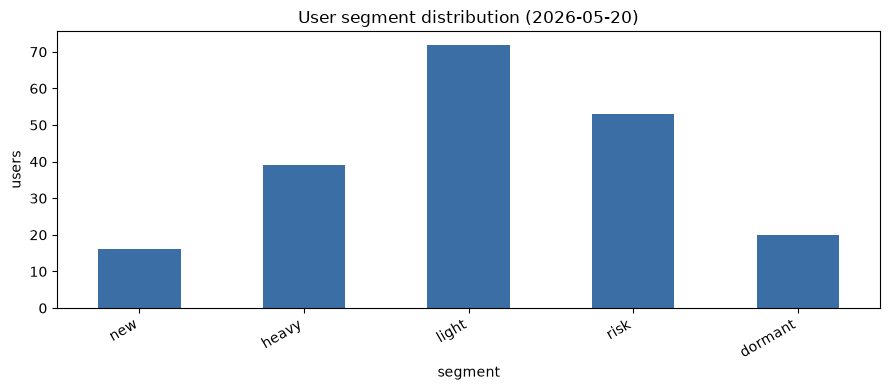

In [10]:
# Daily segment distribution (Stock) — ordering is handled by pandas reindex
dist = con.execute(f"""
SELECT user_seg, count(*) AS users
FROM mart_user_segment
WHERE target_date = DATE '{TARGET}'
GROUP BY user_seg
""").df().set_index("user_seg").reindex(SEG_ORDER)
display(dist)

ax = dist["users"].plot.bar(figsize=(9, 4), color="#3b6ea5")
ax.set_title(f"User segment distribution ({TARGET})")
ax.set_xlabel("segment"); ax.set_ylabel("users")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

This table is a cross-section showing where our service's users are gathered today.
The data mart holds a month of data, so running the same query with different `target_date` values lets you
observe how the segment composition changes. For instance, if the absolute number of heavy users is shrinking while light
is growing at the same time, you can read that as a signal that heavy users are gradually churning.


### 1.3.4.2. Flow - checking the segment transition matrix

From Stock alone, even if the number of heavy users stays about the same as yesterday, you can't tell whether those are the same
users who stayed or whether other users filled the gaps. The easiest way to see that difference is to build a segment transition
matrix. Fortunately, the data mart we built already contains that information —
spread yesterday (`user_seg_from`) across the rows and today (`user_seg`) across the columns, and you have the transition matrix.


In [11]:
# Segment transitions (Flow): yesterday (user_seg_from) → today (user_seg)
trans = con.execute(f"""
SELECT user_seg_from, user_seg, count(*) AS users
FROM mart_user_segment
WHERE target_date = DATE '{TARGET}'
  AND user_seg_from IS NOT NULL   -- exclude users who signed up today (yesterday is NULL)
GROUP BY user_seg_from, user_seg
""").df()

order = SEG_ORDER
pivot = (trans.pivot(index="user_seg_from", columns="user_seg", values="users")
              .reindex(index=order, columns=order))
pivot.fillna(0).astype(int)

user_seg,new,heavy,light,risk,dormant
user_seg_from,,,,,
new,6,1,1,0,0
heavy,0,35,3,0,0
light,0,3,67,4,0
risk,0,0,1,49,1
dormant,0,0,0,0,19


Drawing this matrix as a heatmap shows at a glance where the transitions are concentrated.

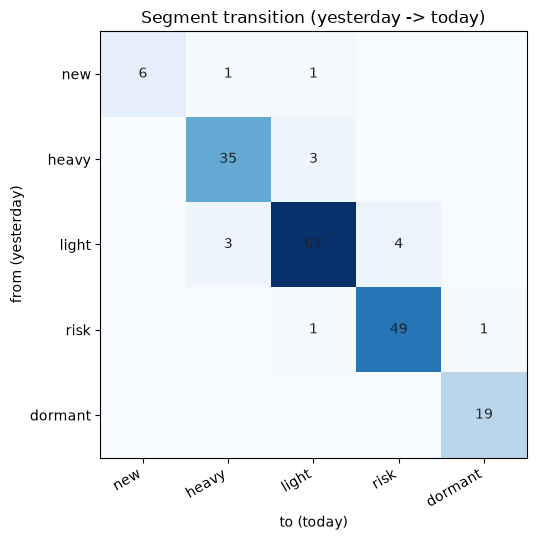

In [12]:
# Transition matrix heatmap
m = pivot.values.astype(float)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(np.nan_to_num(m), cmap="Blues")
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("to (today)"); ax.set_ylabel("from (yesterday)")
for i in range(len(order)):
    for j in range(len(order)):
        if not np.isnan(m[i, j]):
            ax.text(j, i, int(m[i, j]), ha="center", va="center", color="#222")
ax.set_title("Segment transition (yesterday -> today)")
plt.tight_layout(); plt.show()

Rows and columns put new first, followed by the segments from highest activity (heavy) to lowest (dormant).
Of the 8 users who were new yesterday, 6 are still within their first week and remain new, and the 2 who reached day 8 settled
into heavy and light, one each (New Activation). No user fell into risk (New Loss) on this day. The 10 users who signed up
just today have no segment for yesterday, so they are missing from this matrix. That is why the sum of the new column (6)
is smaller than the Stock's new (16). The remaining four rows can be read in three directions, as follows.

1. **Diagonal**: users whose segment is the same yesterday and today. Means they are holding steady.
2. **Above the diagonal** (cells to the right in the same row): users whose activity dropped (e.g. heavy → light, light → risk). The area to monitor for churn signals.
3. **Below the diagonal** (cells to the left in the same row): users whose activity increased (e.g. light → heavy, risk → light). The area that can be read as positive transitions.


### 1.3.4.3. Building ratio metrics

Several meaningful ratio metrics can be extracted from the transition matrix. A few examples
are as follows.

1. **HURR (Heavy → Heavy)**: retention of Heavy users
2. **CURR (Heavy + Light → Heavy + Light)**: retention of Heavy+Light users
3. **Heavy Loss (Heavy → Light)**: share of Heavy users who transitioned to Light
4. **Light Loss (Light → Risk)**: share of Light users who transitioned to Risk
5. **Reactivation (Risk → Light)**: share of Risk users who transitioned to Light

`current`, which groups heavy and light together, is defined as a string constant to insert into the SQL.


In [13]:
current = "('heavy', 'light')"   # currently active users = heavy + light

# Wrap denominators in nullif(..., 0) to guard against division by zero.
kpi = con.execute(f"""
SELECT
  round(100.0 * count_if(user_seg_from = 'heavy' AND user_seg = 'heavy')
    / nullif(count_if(user_seg_from = 'heavy'), 0), 1) AS hurr_pct,
  round(100.0 * count_if(user_seg_from IN {current} AND user_seg IN {current})
    / nullif(count_if(user_seg_from IN {current}), 0), 1) AS curr_pct,
  round(100.0 * count_if(user_seg_from = 'heavy' AND user_seg = 'light')
    / nullif(count_if(user_seg_from = 'heavy'), 0), 1) AS heavy_loss_pct,
  round(100.0 * count_if(user_seg_from = 'light' AND user_seg = 'risk')
    / nullif(count_if(user_seg_from = 'light'), 0), 1) AS light_loss_pct,
  round(100.0 * count_if(user_seg_from = 'risk' AND user_seg = 'light')
    / nullif(count_if(user_seg_from = 'risk'), 0), 1) AS reactivation_pct
FROM mart_user_segment
WHERE target_date = DATE '{TARGET}';
""").df()
kpi.T.rename(columns={0: "pct"})

,pct
hurr_pct,92.1
curr_pct,96.4
heavy_loss_pct,7.9
light_loss_pct,5.4
reactivation_pct,2.0


Once more, here is what each number means.

| Metric | Meaning |
| :-- | :-- |
| HURR 92.1% | Of the users who were heavy yesterday, 92.1% are still heavy today (retained) |
| CURR 96.4% | Of the core active users who were heavy or light yesterday, 96.4% remain so today |
| Heavy Loss 7.9% | Of the users who were heavy yesterday, 7.9% dropped to light |
| Light Loss 5.4% | Of the users who were light yesterday, 5.4% churned to risk |
| Reactivation 2.0% | Of the users who were risk yesterday, 2.0% came back to light |

As you can see, a single query extracts a range of ratio metrics at once. Stack these metrics up day by day
and you can monitor the health of the service at a resolution a plain DAU trend can't come close to.
When interpreting ratio metrics, though, you must always look at the **size of the denominator** as well.
In the example above, Reactivation 2.0% is the result of just 1 out of 51 risk users coming back. For a segment with few people
to begin with, the ratio can swing wildly when only one or two users move. That is why, in practice, it is safer to
show the denominator (segment size) next to the ratio, or to accumulate over a period rather than a single day
to enlarge the denominator before interpreting.


## 1.3.5. Tracking segment change after N days

Everything so far has focused on the change between yesterday and today, i.e. at a 1-day granularity. The 1-day
view fits the data mart's refresh cadence well and is highly immediate, but it also has the drawback that the changes
are so small that meaningful patterns are hard to see. Since a user who was heavy yesterday has a better than 90% chance
of being heavy today, the number HURR 92.1% alone makes it hard to judge whether our heavy users' loyalty is
genuinely solid.

Stretching the time axis and looking at the patterns helps you grasp the transitions between segments.
For example, look at which segments the users who were heavy 30 days ago are split across today, or where the users
who were new 30 days ago are today.

The data mart built in 1.3.3 already holds a month (2026-04-20 ~ 2026-05-20, 31 days), so a
self-join on `user_id` directly links the segment 30 days ago with today's segment. The
`sum(count(*)) OVER ()` in the query below is a window function used to divide each group's count by the overall total,
computing the share (pct) within a single query.

> **[Apply to your data]** To track a longer interval such as 60 or 90 days, move the start date of the date list in 1.3.3
> back by that much and stack more data mart rows first.


,seg_30days_ago,seg_today,users,pct
0,heavy,heavy,25,55.6
1,heavy,light,12,26.7
2,heavy,risk,8,17.8


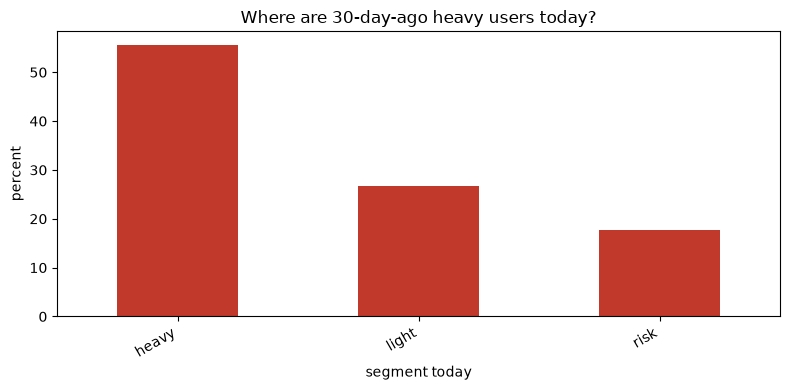

In [14]:
# Where are the users who were heavy 30 days ago today?
nday_query = """
SELECT
  past.user_seg AS seg_30days_ago,
  curr.user_seg AS seg_today,
  count(*) AS users,
  round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct
FROM mart_user_segment AS past
LEFT JOIN mart_user_segment AS curr
  ON past.user_id = curr.user_id
 AND curr.target_date = DATE '{target}'
WHERE past.target_date = DATE '{target}' - INTERVAL 30 DAY
  AND past.user_seg = '{seg}'
GROUP BY past.user_seg, curr.user_seg
ORDER BY users DESC;
"""
nday = con.execute(nday_query.format(seg="heavy", target=TARGET)).df()
display(nday)

ax = nday.set_index("seg_today")["pct"].plot.bar(figsize=(8, 4),
                                                 color="#c0392b")
ax.set_title("Where are 30-day-ago heavy users today?")
ax.set_xlabel("segment today"); ax.set_ylabel("percent")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

Nearly half of the users who were Heavy 30 days ago have scattered into other segments. Let's put this side by side with the 1-day change, using the same HURR definition.


In [15]:
# Compare the same 'heavy retention (HURR)' on two time horizons: 1 day vs. 30 days
con.execute(f"""
WITH one_day AS (    -- heavy yesterday → heavy today
  SELECT round(100.0 * count_if(user_seg_from = 'heavy' AND user_seg = 'heavy')
    / nullif(count_if(user_seg_from = 'heavy'), 0), 1) AS hurr_pct
  FROM mart_user_segment
  WHERE target_date = DATE '{TARGET}'
),
thirty_day AS (      -- heavy 30 days ago → heavy today
  SELECT round(100.0 * count_if(curr.user_seg = 'heavy')
    / nullif(count(*), 0), 1) AS hurr_pct
  FROM mart_user_segment AS past
  LEFT JOIN mart_user_segment AS curr
    ON past.user_id = curr.user_id AND curr.target_date = DATE '{TARGET}'
  WHERE past.target_date = DATE '{TARGET}' - INTERVAL 30 DAY
    AND past.user_seg = 'heavy'
)
SELECT '1 day (yesterday → today)'     AS horizon, hurr_pct FROM one_day
UNION ALL
SELECT '30 days (30 days ago → today)', hurr_pct FROM thirty_day
""").df()

,horizon,hurr_pct
0,1 day (yesterday → today),92.1
1,30 days (30 days ago → today),55.6


Change only the starting segment in the same query to `new`, and you get where the users who were in their first week after signup
30 days ago are today. Where the 1-day New Activation shows the fork at day 8, this table shows
whether they survived to a month later.


In [16]:
# Where are the users who were new 30 days ago today? - N-day settling of new users
nday_new = con.execute(nday_query.format(seg="new", target=TARGET)).df()
nday_new

,seg_30days_ago,seg_today,users,pct
0,new,light,6,60.0
1,new,dormant,2,20.0
2,new,heavy,1,10.0
3,new,risk,1,10.0


The picture these results paint is quite different from the 1-day analysis. On a 1-day basis, **92.1%** of heavy users
are still heavy the next day, but look at the same heavy group on a **30-day** basis and that share falls to **55.6%**.
Small daily churn accumulates over a month, so nearly half of the users who were heavy 30 days ago have scattered into light or
risk. Rather than relaxing because the 1-day HURR is above 90%, you have to look at retention over a longer time axis
as well to gauge how solid the heavy user base really is. (Note that you should not compute long-term retention by multiplying
the 1-day retention N times. It misses users who drop to Light and then climb back to Heavy.)

Of the 10 users who were new 30 days ago, 7 are still heavy or light a month later, and the remaining 3 have fallen into
risk or dormant. Change the `INTERVAL 30 DAY` in `nday_query` to 7 or 14 and you can immediately see the change over
other time axes. To look at longer intervals like 60 or 90 days, move the start date of the date list in 1.3.3 back
by that much and stack more data mart rows first.

The power of this data mart is that, from a single mart loaded daily, you can pull everything from short-term KPIs to
N-day cumulative change on the same structure.
